# Tests and Plots

In [21]:
%load_ext autoreload
%autoreload 2

from random import randint,random
from time import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import emcee

from benchmark_distr import sample_funnel, log_neal_funnel, log_gaussian
from HamiltonianSampler import dchain,NAIVE_NUTS,gaussian_ND


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
rng = np.random.default_rng(42)

## Gaussian:

In [23]:

mean = 80
sigma = 130
means = [randint(20,100),randint(20,100)]
means = [60,30]
nchains = 10


Sigma = np.array([[sigma,0],
         [0,sigma]])

L = 1000 #leapfrog steps
dt = 0.5 #step size
M = np.array([[10000.0,0],
              [0,10000.0]])
N_steps = 100
print("the inverse mass matrix is:",np.linalg.inv(M))

p_start = np.random.normal(0,1)
p_start = np.random.default_rng().multivariate_normal([0,0], M, size=1)

#now computes alll chains at once
start_time = time()
X0s = [[random()*100,random()*100] for i in range(nchains)]
"""
Xns = np.array(dchain(np.array(X0s),N_steps,dt,L,M,method="gaussian"))
print((time()-start_time)/60)
for i in range(10):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()

for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))"""

the inverse mass matrix is: [[0.0001 0.    ]
 [0.     0.0001]]


'\nXns = np.array(dchain(np.array(X0s),N_steps,dt,L,M,method="gaussian"))\nprint((time()-start_time)/60)\nfor i in range(10):\n    plt.plot(Xns[:,i,0],Xns[:,i,1])\n\n\n#Grid\nx = np.linspace(0,100,100)\ny = np.linspace(0,100,100)\nX,Y = np.meshgrid(x,y)\npos = np.dstack((X,Y))\n\nZ = multivariate_normal(means,Sigma).pdf(pos)\n\n\n\n\ncf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")\n#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)\nplt.colorbar(cf)\nplt.show()\n\nfor Xn in Xns:\n    plt.plot(Xn[:,0])\n    plt.plot(Xn[:,1])\nplt.show()\nprint(np.mean(Xn[:,0]),np.mean(Xn[:,1]))'

In [ ]:
N_steps = 100
print("the inverse mass matrix is:",np.linalg.inv(M))

p_start = np.random.normal(0,1)
p_start = np.random.default_rng().multivariate_normal([0,0], M, size=1)

#now computes alll chains at once
start_time = time()
X0s = [[random()*100,random()*100] for i in range(nchains)]

#NAIVE NUTS
logp = lambda x: np.log(gaussian_ND(x,means,Sigma))
start_time = time()
Xns = np.array(NAIVE_NUTS(np.array(X0s),dt,logp,N_steps,np.eye(2)))
print((time()-start_time)/60)
for i in range(nchains):
    plt.plot(Xns[i,:,0],Xns[i,:,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()

for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))


the inverse mass matrix is: [[0.0001 0.    ]
 [0.     0.0001]]


100%|██████████| 1000/1000 [00:00<00:00, 1524.69it/s]


chain shape: (1000, 10, 2)


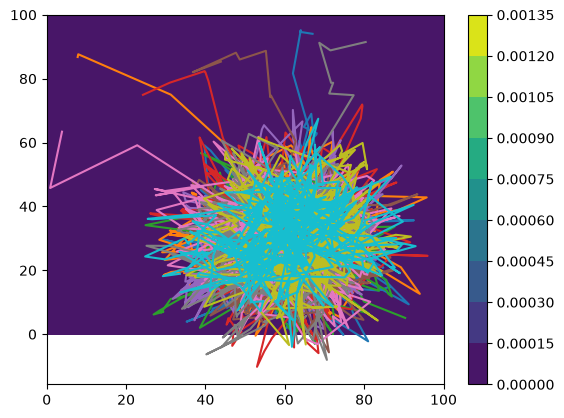

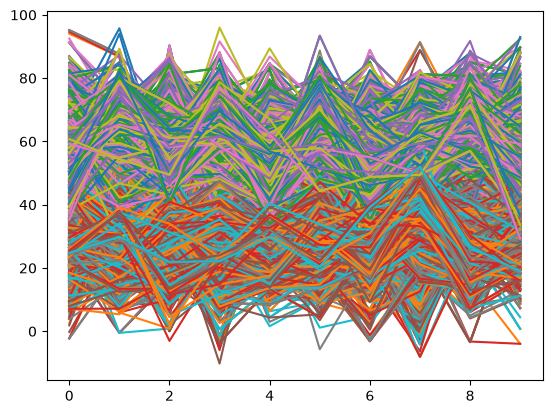

55.810992374899136 28.571832259510536


In [ ]:
nsteps, nwalkers, ndim = L, nchains, 2
#burnin = nsteps // 5


sampler = emcee.EnsembleSampler(nwalkers,ndim,log_gaussian,args=(means,Sigma))

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()


for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))


## Neal's Funnel:

100%|██████████| 100/100 [00:00<00:00, 2104.55it/s]


chain shape: (100, 10, 2)


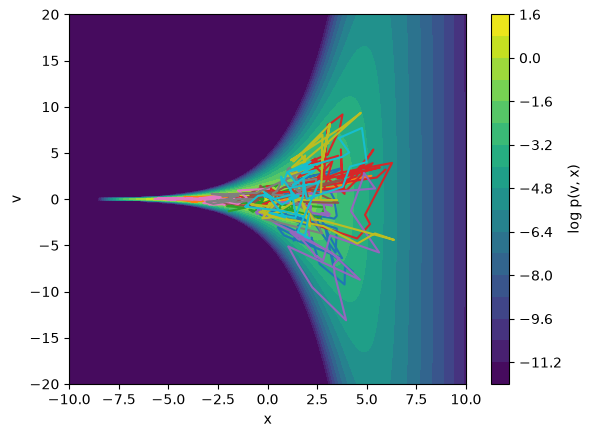

In [ ]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()

100%|██████████| 100/100 [00:00<00:00, 2483.72it/s]


chain shape: (100, 10, 2)


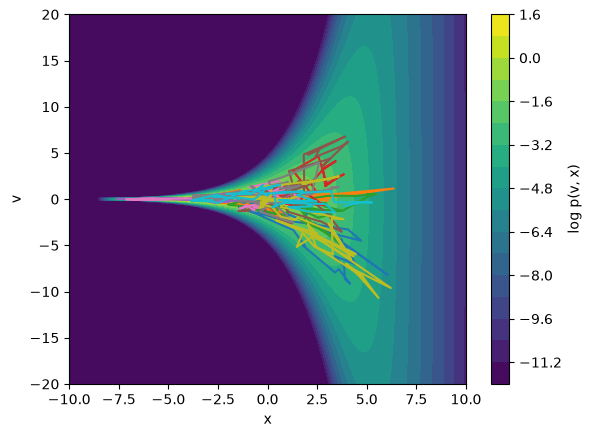

In [ ]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()
